<a href="https://colab.research.google.com/github/cdube89128/DATA_620/blob/main/DATA_620_Week_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Homework
### DATA 620
### Catherine Dube

**HW Prompt**

This assignment is:

* Here is a dataset that shows a simple 2-node network:  the attendance of 18 Southern Women at 14 social events:
  * [Brief Description](http://vlado.fmf.uni-lj.si/pub/networks/data/ucinet/ucidata.htm#davis). Small “musty” datasets like that from this 1941 study have proven very valuable in testing and comparing new network algorithms.
  * [Dataset](http://vlado.fmf.uni-lj.si/pub/networks/data/Ucinet/davis.dat).
  * Python code to create dataset: https://networkx.github.io/documentation/stable/auto_examples/algorithms/plot_davis_club.html
* What can you infer about the relationships between (1) the women, and (2) the social events?  

*quick note: I could not get the [Brief Description](http://vlado.fmf.uni-lj.si/pub/networks/data/ucinet/ucidata.htm#davis) or [Dataset](http://vlado.fmf.uni-lj.si/pub/networks/data/Ucinet/davis.dat) links to open successfully. But the Python code link to create the dataset worked, so I am working off of that and the textbook content.*

# Homework Starts Below

I walk through my exploration of the data first. My answer to "What can you infer about the relationships between (1) the women, and (2) the social events?" is at the very bottom.

### Setup

In [18]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns
from networkx.algorithms import bipartite


### Import Data

In [19]:
# Set visual theme
sns.set_theme(style='whitegrid', palette='colorblind')

# Load Davis Southern Women 2-Mode Graph
G = nx.davis_southern_women_graph()

# Extract top (Women) and bottom (Events) node sets
women = G.graph["top"]
events = G.graph["bottom"]

print(f"Bipartite Graph Loaded:")
print(f"Total Nodes: {G.number_of_nodes()} (18 Women, 14 Events)")
print(f"Total Edges (Attendances): {G.number_of_edges()}")

Bipartite Graph Loaded:
Total Nodes: 32 (18 Women, 14 Events)
Total Edges (Attendances): 89


### Biadjacency Matrix

Because this data set has two different node types (Women and Events), I am going to make a Biadjacency matrix to get an image of the number of events the women attended.

In [20]:
# Create Biadjacency Matrix
bi_matrix = bipartite.biadjacency_matrix(G, women, events).toarray()
matrix_df = pd.DataFrame(bi_matrix, index=women, columns=events)

print("Davis Southern Women Attendance Matrix (1 = Attended, 0 = Did Not Attend)")
display(matrix_df.head(100))

Davis Southern Women Attendance Matrix (1 = Attended, 0 = Did Not Attend)


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Evelyn Jefferson,1,1,1,1,1,1,0,1,1,0,0,0,0,0
Laura Mandeville,1,1,1,0,1,1,1,1,0,0,0,0,0,0
Theresa Anderson,0,1,1,1,1,1,1,1,1,0,0,0,0,0
Brenda Rogers,1,0,1,1,1,1,1,1,0,0,0,0,0,0
Charlotte McDowd,0,0,1,1,1,0,1,0,0,0,0,0,0,0
Frances Anderson,0,0,1,0,1,1,0,1,0,0,0,0,0,0
Eleanor Nye,0,0,0,0,1,1,1,1,0,0,0,0,0,0
Pearl Oglethorpe,0,0,0,0,0,1,0,1,1,0,0,0,0,0
Ruth DeSand,0,0,0,0,1,0,1,1,1,0,0,0,0,0
Verne Sanderson,0,0,0,0,0,0,1,1,1,0,0,1,0,0


Next I am going to pull in a few simple summary statistics to help give me an image of how many women are attending events. How many events on average is each woman attending. Etc.

In [21]:
deg_dict = dict(getattr(G, 'degree')())

#Total Event Attendances (Total Edges)
total_attendances = G.number_of_edges()

#Active Women Count
active_women = [w for w in women if deg_dict[w] > 0]

#Average Attendances per Woman
avg_attendances = total_attendances / len(women)

# Event Attendance Count per Woman
women_counts = pd.DataFrame({
    'Woman': women,
    'Events_Attended': [deg_dict[w] for w in women]
}).sort_values(by='Events_Attended', ascending=False)

# Attendance Size per Social Event
event_counts = pd.DataFrame({
    'Event': events,
    'Total_Attendees': [deg_dict[e] for e in events]
}).sort_values(by='Total_Attendees', ascending=False)

# Display Summary
print(f"Total Network Attendances: {total_attendances}")
print(f"Active Women: {len(active_women)} out of {len(women)}")
print(f"Average Events Attended per Woman: {avg_attendances:.2f}\n")

print("Top 5 Women by Events Attended:")
print(women_counts.head(5).to_string(index=False))

print("\nTop 5 Social Events by Attendance:")
print(event_counts.head(5).to_string(index=False))

Total Network Attendances: 89
Active Women: 18 out of 18
Average Events Attended per Woman: 4.94

Top 5 Women by Events Attended:
           Woman  Events_Attended
Evelyn Jefferson                8
Theresa Anderson                8
    Nora Fayette                8
Laura Mandeville                7
 Sylvia Avondale                7

Top 5 Social Events by Attendance:
Event  Total_Attendees
   E8               14
   E9               12
   E7               10
   E5                8
   E6                8


###  1-Mode Projections (Women & Events)
Next, I will project the 2-mode network into weighted 1-mode graphs to transform indirect event memberships into direct measurements of shared co-attendance and event overlap.

In [29]:
# Women-to-Women Weighted Projection
W_proj = bipartite.weighted_projected_graph(G, women)

# Events-to-Events Weighted Projection
E_proj = bipartite.weighted_projected_graph(G, events)

# Safely extract degree functions
get_woman_deg = getattr(W_proj, 'degree')
get_event_deg = getattr(E_proj, 'degree')

# Summary Table for Women
women_summary = pd.DataFrame({
    'Woman': women,
    'Unique_Co_Members': [get_woman_deg(w) for w in women],
    'Total_Shared_Attendances': [get_woman_deg(w, weight='weight') for w in women]
}).sort_values(by='Total_Shared_Attendances', ascending=False)

print("Women Order by Shared Event Attendances: ")
print(women_summary.head(20))

print("\n")

# Summary Table for Events
events_summary = pd.DataFrame({
    'Event': events,
    'Unique_Women_Connected': [get_event_deg(e) for e in events],
    'Total_Attendee_Overlap': [get_event_deg(e, weight='weight') for e in events]
}).sort_values(by='Total_Attendee_Overlap', ascending=False)

print("Events Ordered by Attendee Overlap: ")
print(events_summary.head(20))

Women Order by Shared Event Attendances: 
                Woman  Unique_Co_Members  Total_Shared_Attendances
2    Theresa Anderson                 17                        57
0    Evelyn Jefferson                 17                        50
12    Sylvia Avondale                 17                        46
3       Brenda Rogers                 15                        46
1    Laura Mandeville                 15                        45
13       Nora Fayette                 17                        43
8         Ruth DeSand                 17                        40
9     Verne Sanderson                 17                        38
11   Katherina Rogers                 16                        37
6         Eleanor Nye                 15                        36
14        Helen Lloyd                 17                        34
10        Myra Liddel                 16                        33
5    Frances Anderson                 15                        32
7    Pearl Oglethorp

 From this, I see that some specific women, like Theresa Anderson and Evelyn Jefferson, are the center of social influence. And of the events, E6 through E9 have the most unique women connected. But E9 has the heighest weighted overlap at 59. That means that cliques or groups of the *same* women are attending E8 together.


### Visualizations

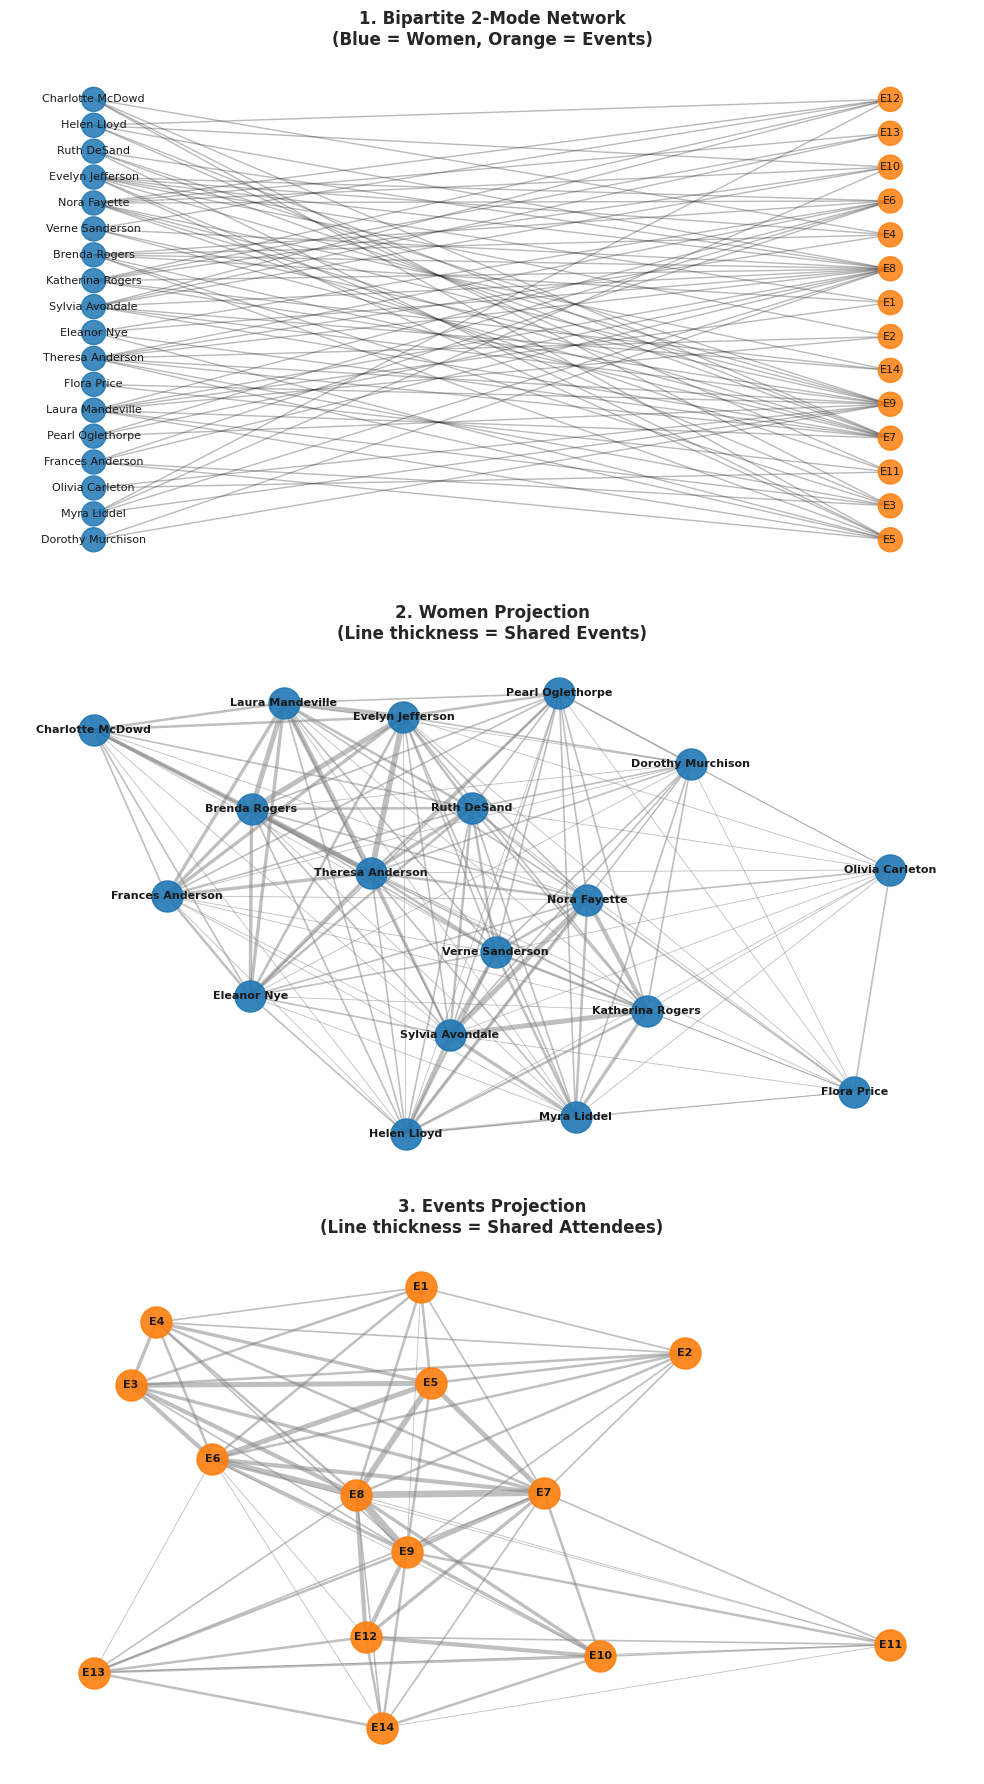

In [27]:
# Create 3 stacked rows (3 rows, 1 column)
# Easier to view the final graphs this way
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# 2-Mode Bipartite Network
pos_bipartite = nx.bipartite_layout(G, women)
node_colors = ['#1f77b4' if node in women else '#ff7f0e' for node in G.nodes()]

nx.draw_networkx_nodes(G, pos_bipartite, ax=axes[0], node_color=node_colors, node_size=300, alpha=0.85)
nx.draw_networkx_edges(G, pos_bipartite, ax=axes[0], alpha=0.3)
nx.draw_networkx_labels(G, pos_bipartite, ax=axes[0], font_size=8)
axes[0].set_title("1. Bipartite 2-Mode Network\n(Blue = Women, Orange = Events)", fontweight='bold')
axes[0].axis('off')

# Women Projection (Weighted)
pos_women = nx.spring_layout(W_proj, seed=42)
weights_w = [W_proj[u][v]['weight'] for u, v in W_proj.edges()]

nx.draw_networkx_nodes(W_proj, pos_women, ax=axes[1], node_color='#1f77b4', node_size=500, alpha=0.9)
nx.draw_networkx_edges(W_proj, pos_women, ax=axes[1], width=[w * 0.6 for w in weights_w], alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(W_proj, pos_women, ax=axes[1], font_size=8, font_weight='bold')
axes[1].set_title("2. Women Projection\n(Line thickness = Shared Events)", fontweight='bold')
axes[1].axis('off')

# Events Projection (Weighted)
pos_events = nx.spring_layout(E_proj, seed=42)
weights_e = [E_proj[u][v]['weight'] for u, v in E_proj.edges()]

nx.draw_networkx_nodes(E_proj, pos_events, ax=axes[2], node_color='#ff7f0e', node_size=500, alpha=0.9)
nx.draw_networkx_edges(E_proj, pos_events, ax=axes[2], width=[w * 0.6 for w in weights_e], alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(E_proj, pos_events, ax=axes[2], font_size=8, font_weight='bold')
axes[2].set_title("3. Events Projection\n(Line thickness = Shared Attendees)", fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
render = getattr(plt, 'show')
render()

Okay, I am often a visual person, but honestly these graphs don't help me see the biggest connection points in this graph. The Biadjacency Matrix probably helped me see it the best.

### Final Responses

**What can you infer about the relationships between the women?**

Especially using the Biadjacency matrix earlier, I saw sort of two groups of women clustering.

* In the earlier numbered events (like before E7), I saw  Evelyn Jefferson, Laura Mandeville, Theresa Anderson, and Brenda Rogers more frequently. 1 cluster of women.
* In the later numbered events (like E10 and later), I saw Sylvia Avondale, Nora Fayette, and Katherina Rogers. A 2nd cluster of women.
* Earlier, I saw that there are a few women who went the events in the middle, Pearl Oglethorpe, Ruth DeSand, and Charlotte McDowd. They are the boundary spanners because they connect the two groups


**What can you infer about the relationships between the social events?**

* I can flip the same information I used for the first questiona and apply it here. The early events are most frequented by one group of women, while the later events are most frequented by a different group of women.

* Then in the middle, E7, E8, and E9 each connect to all 13 other events on the calendar. So they shared at least one attendee with every other event.

* E8 had the highest turnout overall (14 out of 18 women attended) and the highest Total Attendee Overlap (59). That makes it the bridging event, bringing the women together

